# EarthCARE trackwise dataset and baseline results

This notebook covers the **EarthCARE benchmark**: should the Cloud Profiling Radar (CPR) be
switched on this minute, decided only from what the passive Multi-Spectral Imager (MSI) and
the orbit geometry can see?

It has two parts:

1. **The dataset**: how it was built, integrity checks, and what the weather in it looks like.
2. **The baseline results** (experiments E1–E11): how well simple, fixed policies can decide
   when to switch the radar on under a power budget. These are the numbers any RL agent has
   to beat.

Nothing here downloads data or re-runs the extraction. The notebook reads
`data/EarthCare_trackwise_decisions.parquet` and the CSVs in `results/`, and takes the orbit
and time-window settings directly from `extract_trackwise.py`, so it always matches the
pipeline that produced the data.

**Rebuild everything** (from the repository root):

```
python3 extract_trackwise.py                                    # weather along the orbit, 59 blocks
python3 task_outputs/fetch_g5nr_constants.py                    # once: land/water grid
python3 task_outputs/enrich_trackwise.py <extraction cache dir> # -> data/
python  -m baselines.run_baselines --mission earthcare          # -> results/
```

## 1. How the dataset was built

| step | what happens |
|---|---|
| **orbit** | EarthCARE's position every second, from a set of real TLEs (NORAD 59908) covering 2025-06-01 → 2026-02-01. The TLE closest in time is used for each moment, so orbit manoeuvres are followed. |
| **weather** | GEOS-5 Nature Run (G5NR), a 7 km global simulation, sampled every 30 minutes at 0.0625°. |
| **time alignment** | The orbit runs in 2025, the weather is from 2005. Each orbit minute is paired with the G5NR snapshot at the **same day of year and the same UTC time** (orbit 2025-06-01 15:00 ↔ G5NR 2005-06-01 15:00, step 803), so the season and the local solar time are both correct. |
| **decision** | One row per minute: should the CPR be on? 30 decisions share each 30-minute weather snapshot. |
| **passive features** | MSI-like cloud diagnostics averaged over the MSI swath under the satellite during that minute (cloud fraction, cloud-top temperature, optical depth, outgoing longwave). |
| **targets** | Precipitation, ice and liquid water: the maximum along the **nadir** track (what the CPR actually measures) and over the whole **swath**. |
| **enrichment** | Land/water fraction under the track, cyclic longitude, solar hour, next-minute longwave (`lwtup_fore`), validity flags. |

One block of the extraction (block 13) received a corrupted server response that put
precipitation of up to 60,030 kg m⁻² s⁻¹ in 3 rows over Antarctica. The block was re-downloaded,
and the re-run matched the original in every value except those 3 rows. The range check in
§2 verifies that no physically impossible values remain.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve().parents[1]                 # notebook lives in missions/earthcare/
assert (ROOT / "extract_trackwise.py").exists(), f"run this notebook from missions/earthcare/ ({ROOT})"
sys.path.insert(0, str(ROOT))
import extract_trackwise as X                          # the pipeline's own settings

MISSION = ROOT / "missions" / "earthcare"
DATA = MISSION / "data" / "EarthCare_trackwise_decisions.parquet"
RES = MISSION / "results"
MM = 3600.0                                            # kg m-2 s-1 -> mm/hr
RAIN = 1.0 / MM                                        # benchmark label: >= 1 mm/hr at nadir

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

n_tle, ep0, ep1, gap = X.check_tle_coverage(X.startdate + X.N_FIELDS * X.G5_STEP)
print(f"orbit      : {Path(X.TLE_FILE).relative_to(ROOT)}  ({n_tle} TLEs, "
      f"{ep0:%Y-%m-%d} .. {ep1:%Y-%m-%d}, largest gap {gap})")
print(f"orbit start: {X.startdate:%Y-%m-%d %H:%M} UTC  <->  G5NR step {X.FIELD_START}")
print(f"window     : {X.N_FIELDS:,} weather steps x {X.PER_FIELD} decisions = "
      f"{X.N_FIELDS * X.PER_FIELD:,} one-minute decisions "
      f"({X.N_FIELDS * X.G5_STEP.total_seconds() / 86400:.0f} days)")

orbit      : missions/earthcare/tle/sat000059908.txt  (593 TLEs, 2025-05-25 .. 2026-02-08, largest gap 2 days, 13:41:53.252747)
orbit start: 2025-06-01 15:00 UTC  <->  G5NR step 803
window     : 11,760 weather steps x 30 decisions = 352,800 one-minute decisions (245 days)


## 2. Load the dataset and check it

These checks fail loudly if the file does not match the pipeline: every decision present
exactly once, each row tied to the right weather step, the hash matching the enrichment
report and the baseline run, and every weather value within physical limits.

In [2]:
rows = pd.read_parquet(DATA)
report = json.loads((MISSION / "data" / "enrich_report.json").read_text())
meta = json.loads((RES / "run_meta.json").read_text())

N = X.N_FIELDS * X.PER_FIELD
assert rows.shape == (N, 40), rows.shape
assert np.array_equal(rows.decision.to_numpy(), np.arange(N)), "decisions are not 0..N-1"
assert (rows.g5_step == X.FIELD_START + rows.decision // X.PER_FIELD).all()
assert report["sha256"] == meta["data_sha256"], "results were computed on a different dataset"

import hashlib
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == report["sha256"], "parquet changed since enrichment"

# physical limits; G5NR precipitation never comes close to 0.1 kg m-2 s-1 (360 mm/hr)
LIMITS = {"cldtot_mean": (0, 1), "cldhgh_mean": (0, 1), "cldmid_mean": (0, 1), "cldlow_mean": (0, 1),
          "tautot_mean": (0, 1e3), "tautot_max": (0, 1e3), "cldtmp_mean": (150, 330),
          "lwtup_mean": (50, 450), "lwtup_fore": (50, 450),
          "prectot_swath": (0, 0.1), "prectot_nadir": (0, 0.1),
          "preccon_swath": (0, 0.1), "preccon_nadir": (0, 0.1),
          "iwp_swath": (0, 20), "iwp_nadir": (0, 20), "lwp_swath": (0, 20), "lwp_nadir": (0, 20)}
audit = pd.DataFrame([{"column": c, "min": rows[c].min(), "max": rows[c].max(),
                       "NaN": int(rows[c].isna().sum()),
                       "out of range": int((rows[c].notna() & ~rows[c].between(lo, hi)).sum())}
                      for c, (lo, hi) in LIMITS.items()])
assert audit["out of range"].sum() == 0
display(audit.set_index("column"))

print(f"{len(rows):,} decisions x {rows.shape[1]} columns, sha256 {report['sha256'][:16]}...")
print(f"time: {rows.time.min():%Y-%m-%d %H:%M} -> {rows.time.max():%Y-%m-%d %H:%M} UTC (orbit clock)")
print(f"locations replaced by the nadir point (poles / dateline): {report['locations_replaced_by_nadir']:,}")
print(f"cldtmp_mean NaN: {report['nan_counts']['cldtmp_mean']:,} (no cloud top to report);  "
      f"lwtup_fore NaN: {report['lwtup_fore_nan']:,} (one per weather step: the last minute "
      "before the snapshot changes)")

,min,max,NaN,out of range
column,,,,
cldtot_mean,0.000000,1.000000,0,0
cldhgh_mean,0.000000,0.977791,0,0
cldmid_mean,0.000000,0.973180,0,0
cldlow_mean,0.000000,0.999979,0,0
tautot_mean,0.000000,227.061157,0,0
tautot_max,0.000000,430.319794,0,0
cldtmp_mean,192.827820,302.910645,17425,0
lwtup_mean,79.872742,388.517242,0,0
lwtup_fore,79.872742,385.902618,11760,0


352,800 decisions x 40 columns, sha256 9fe09a93c8b0640f...
time: 2025-06-01 15:00 -> 2026-02-01 14:59 UTC (orbit clock)
locations replaced by the nadir point (poles / dateline): 5,818
cldtmp_mean NaN: 17,425 (no cloud top to report);  lwtup_fore NaN: 11,760 (one per weather step: the last minute before the snapshot changes)


## 3. How often does it rain?

The benchmark label is **"precipitation ≥ 1 mm/hr at nadir"**, i.e. rain the CPR would
actually see. The swath column counts rain anywhere in the 150 km MSI swath, much of which
the nadir-pointing CPR never flies over.

,prectot_nadir (%),prectot_swath (%),preccon_nadir (%),preccon_swath (%)
>= 0.1 mm/hr,49.4,67.0,16.1,23.5
>= 0.5 mm/hr,22.4,41.8,3.3,9.5
>= 1 mm/hr,13.7,30.0,1.2,5.0
>= 5 mm/hr,3.8,11.8,0.2,1.8
>= 10 mm/hr,2.0,7.6,0.1,0.9


At the 1 mm/hr label, 13.7% of minutes have rain at nadir and 30.0% somewhere in the swath: the swath label would credit the radar with 2.2x more rain than it can measure.


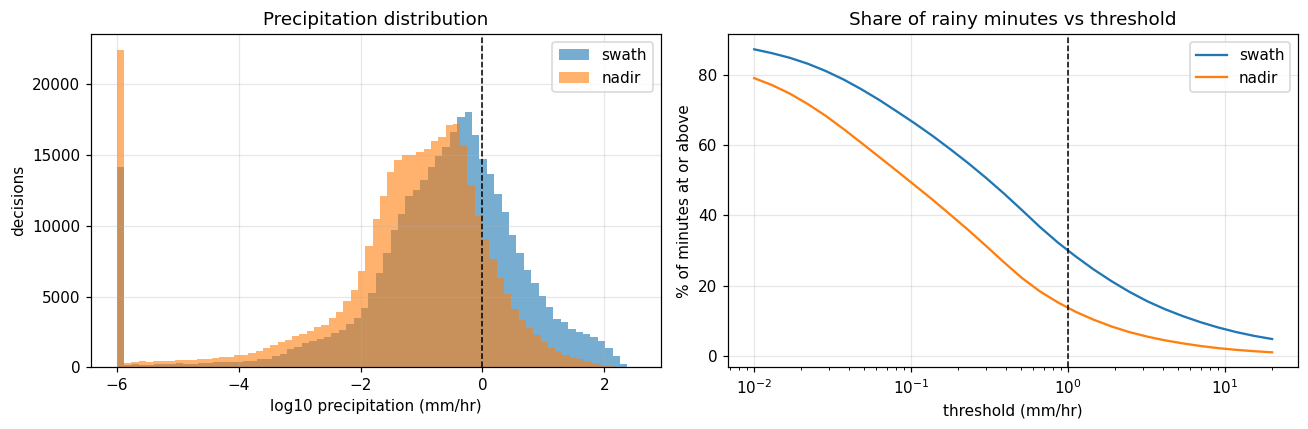

In [3]:
TARGETS = ["prectot_nadir", "prectot_swath", "preccon_nadir", "preccon_swath"]
THRESH = [0.1, 0.5, 1, 5, 10]
balance = pd.DataFrame({c: [100 * (rows[c] >= t / MM).mean() for t in THRESH] for c in TARGETS},
                       index=[f">= {t:g} mm/hr" for t in THRESH]).round(1)
display(balance.rename(columns=lambda c: c + " (%)"))
nad, sw = balance.loc[">= 1 mm/hr", "prectot_nadir"], balance.loc[">= 1 mm/hr", "prectot_swath"]
print(f"At the 1 mm/hr label, {nad:.1f}% of minutes have rain at nadir and {sw:.1f}% somewhere "
      f"in the swath: the swath label would credit the radar with {sw / nad:.1f}x more rain "
      "than it can measure.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, lb in [("prectot_swath", "swath"), ("prectot_nadir", "nadir")]:
    v = rows[c].clip(lower=1e-6 / MM) * MM
    ax[0].hist(np.log10(v), bins=70, alpha=.6, label=lb)
    th = np.logspace(-2, 1.3, 30)
    ax[1].plot(th, [100 * (rows[c] >= t / MM).mean() for t in th], label=lb)
ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set(xlabel="log10 precipitation (mm/hr)", ylabel="decisions", title="Precipitation distribution")
ax[1].axvline(1, color="k", ls="--", lw=1)
ax[1].set(xscale="log", xlabel="threshold (mm/hr)", ylabel="% of minutes at or above",
          title="Share of rainy minutes vs threshold")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 4. Where and when it rains along the orbit

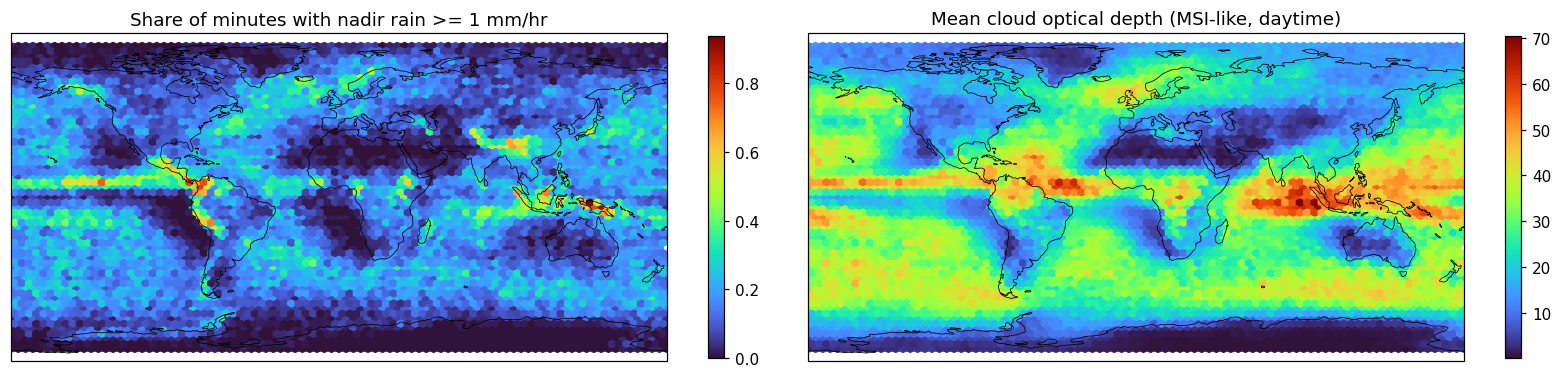

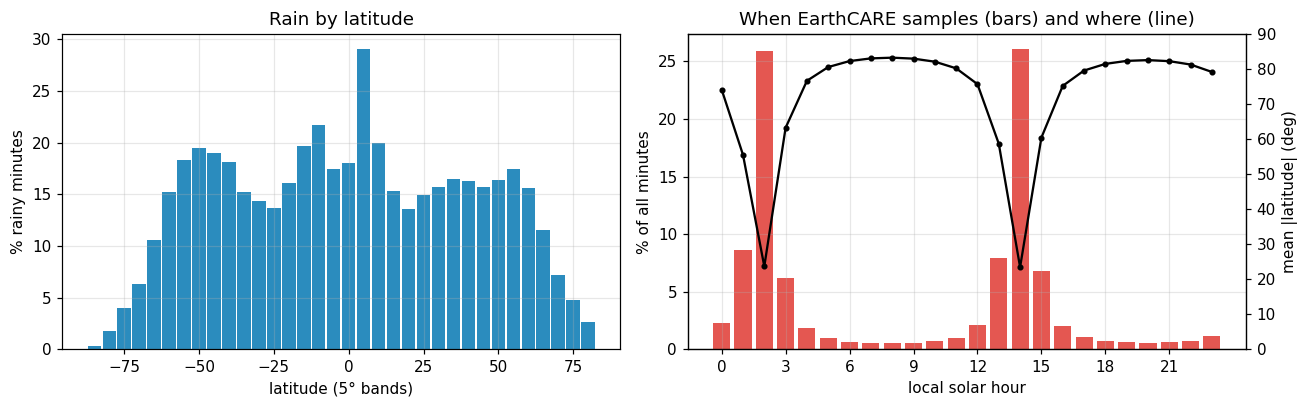

Sun-synchronous orbit: 82% of minutes fall in the 6 hours around 14:00 and 2:00 local time (mean |lat| 23 deg at the peak). The other hours are only reached near the poles (mean |lat| up to 83 deg), so in this dataset time of day and latitude cannot be separated: the benchmark covers EarthCARE's ~14:00/02:00 sampling only.


In [4]:
import cartopy.crs as ccrs

rows["rain"] = rows.prectot_nadir >= RAIN
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), subplot_kw={"projection": ccrs.PlateCarree()})
for a, (col, title, red) in zip(ax, [
        ("rain", "Share of minutes with nadir rain >= 1 mm/hr", np.mean),
        ("tautot_mean", "Mean cloud optical depth (MSI-like, daytime)", np.nanmean)]):
    d = rows if col == "rain" else rows[rows.tautot_mean > 0]
    hb = a.hexbin(d.lon, d.lat, C=d[col].astype(float), gridsize=(90, 30), cmap="turbo",
                  reduce_C_function=red, mincnt=20, transform=ccrs.PlateCarree())
    a.coastlines(linewidth=0.5); a.set_global(); a.set_title(title)
    plt.colorbar(hb, ax=a, shrink=0.75)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
lat = rows.groupby(rows.lat // 5 * 5).rain.mean() * 100
ax[0].bar(lat.index, lat.values, width=4.5, color="#2b8cbe")
ax[0].set(xlabel="latitude (5° bands)", ylabel="% rainy minutes", title="Rain by latitude")
sh = rows.assign(alat=rows.lat.abs()).groupby(rows.solar_hour.round().mod(24)).agg(
    n=("rain", "size"), alat=("alat", "mean"))
ax[1].bar(sh.index, 100 * sh.n / len(rows), color="#de2d26", alpha=.8)
ax[1].set(xlabel="local solar hour", ylabel="% of all minutes", xticks=range(0, 24, 3),
          title="When EarthCARE samples (bars) and where (line)")
ax2 = ax[1].twinx()
ax2.plot(sh.index, sh.alat, "k.-"); ax2.set(ylabel="mean |latitude| (deg)", ylim=(0, 90)); ax2.grid(False)
plt.tight_layout(); plt.show()
busy = sh.n.nlargest(6)
print(f"Sun-synchronous orbit: {100 * busy.sum() / len(rows):.0f}% of minutes fall in the 6 hours around "
      f"{sh.n.idxmax():.0f}:00 and {(sh.n.idxmax() + 12) % 24:.0f}:00 local time (mean |lat| "
      f"{sh.loc[sh.n.idxmax(), 'alat']:.0f} deg at the peak). The other hours are only reached near the "
      f"poles (mean |lat| up to {sh.alat.max():.0f} deg), so in this dataset time of day and latitude "
      "cannot be separated: the benchmark covers EarthCARE's ~14:00/02:00 sampling only.")

## 5. Dataset structure checks

* **Land/water** under the nadir track, averaged over the minute's 60 one-second points.
* **Cyclic longitude**: `sin_lon`/`cos_lon` put −180° and +180° next to each other.
* **Persistence**: how quickly rain and clouds change from one minute to the next. This
  matters for an RL agent: if consecutive minutes were near-identical, "do what you did
  last minute" would be a strong policy.

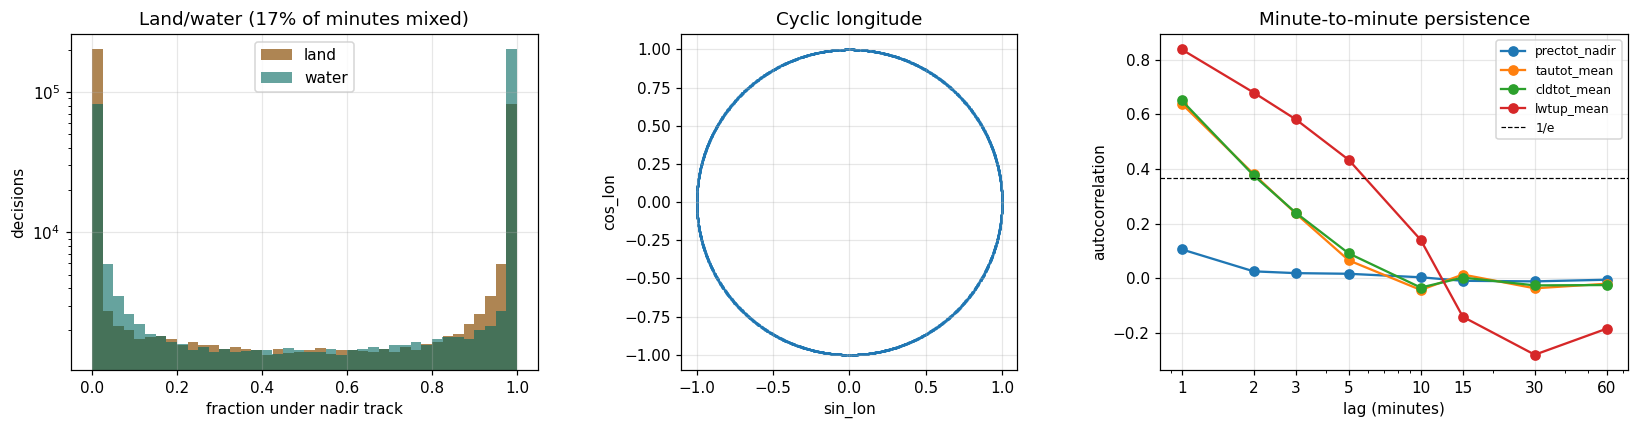

lag-1 autocorrelation: prectot_nadir 0.11, tautot_mean 0.64, cldtot_mean 0.65, lwtup_mean 0.84
The satellite moves ~450 km per minute, so nadir rain one minute says little about the next.


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(rows.land_frac_nadir, bins=40, alpha=.7, color="#8c510a", label="land")
ax[0].hist(rows.ocean_frac_nadir, bins=40, alpha=.6, color="#01665e", label="water")
ax[0].set(xlabel="fraction under nadir track", ylabel="decisions", yscale="log",
          title=f"Land/water ({100 * report['mixed_surface_share']:.0f}% of minutes mixed)")
ax[0].legend()

ax[1].scatter(rows.sin_lon.iloc[::25], rows.cos_lon.iloc[::25], s=.4, alpha=.2)
ax[1].set(aspect="equal", xlabel="sin_lon", ylabel="cos_lon", title="Cyclic longitude")

lags = [1, 2, 3, 5, 10, 15, 30, 60]
for c in ["prectot_nadir", "tautot_mean", "cldtot_mean", "lwtup_mean"]:
    s = rows[c]
    ax[2].plot(lags, [s.autocorr(k) for k in lags], marker="o", label=c)
ax[2].axhline(np.exp(-1), color="k", ls="--", lw=.8, label="1/e")
ax[2].set(xscale="log", xticks=lags, xlabel="lag (minutes)", ylabel="autocorrelation",
          title="Minute-to-minute persistence")
ax[2].get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("lag-1 autocorrelation: " + ", ".join(f"{c} {rows[c].autocorr(1):.2f}" for c in
      ["prectot_nadir", "tautot_mean", "cldtot_mean", "lwtup_mean"]))
print("The satellite moves ~450 km per minute, so nadir rain one minute says little about the next.")

---
# Part 2. Baseline results (E1–E11)

## How to read the results

**The task.** For each minute in the **test period (Nov 2005 – Jan 2006)**, a policy gives a
score. The radar is switched on for the highest-scoring minutes, up to a power budget.

**Key terms**

| term | meaning |
|---|---|
| **duty cycle *d*** | share of minutes the radar is on (the power budget). 20% = on for 1 minute in 5. |
| **capture@d** | share of rainy minutes (≥ 1 mm/hr at nadir) that fall in the radar-on minutes. The main metric. Random gets *d*. |
| **mass-capture@d** | share of the total *amount* of rain in radar-on minutes (heavy rain counts more). |
| **AUC** | how well the score ranks rainy above dry minutes overall (0.5 = random, 1 = perfect). |
| **AP** | average precision; like AUC but focused on the rare rainy minutes (random = rain rate ≈ 0.13). |

**The policies** (fixed rules, no learning after deployment)

| policy | what it uses |
|---|---|
| P1 random | nothing: switches on at random |
| P2 geometry LR | logistic regression on where/when only (latitude, longitude, solar hour, land/water) |
| P3 latitude band | the training rain rate of the current 5° latitude band |
| P4 single threshold | one passive feature: optical depth by day, cloud-top temperature by night |
| P5 logistic regression | linear model on all passive features + geometry (Tier A) |
| P6 gradient boosting | LightGBM on the same features: non-linear, the strongest baseline |
| P7 MLP | small neural network (two hidden layers of 64) on the same features |
| P8 oracle | knows the true rain: the upper bound, not achievable |

**How the numbers are made honest.** Models are trained on Jun–Sep 2005, the decision
threshold for each budget is set on Oct 2005, and everything is scored on Nov 2005 – Jan 2006.
One weather step is dropped at each boundary so no 30-minute snapshot appears on both sides.

In [6]:
r = lambda name: pd.read_csv(RES / f"{name}.csv")
pct = lambda x: f"{100 * x:.1f}%"
print(f"label: {meta['label']}  |  split: train {meta['split']['train'][0]}..{meta['split']['train'][-1]}, "
      f"val {meta['split']['val'][0]}, test {meta['split']['test'][0]}..{meta['split']['test'][-1]}")
print(f"results computed on sha256 {meta['data_sha256'][:16]}... with lightgbm {meta['lightgbm']}, "
      f"sklearn {meta['sklearn']}")

label: prectot_nadir >= 0.000277778 kg m-2 s-1  |  split: train 2005-06..2005-09, val 2005-10, test 2005-11..2006-02
results computed on sha256 9fe09a93c8b0640f... with lightgbm 4.7.0, sklearn 1.6.1


## E3. Main result: how much rain does each policy catch?

The curve shows capture as the duty cycle grows. A good policy rises steeply on the left:
it catches a lot of rain while the radar is on only a small share of the time.

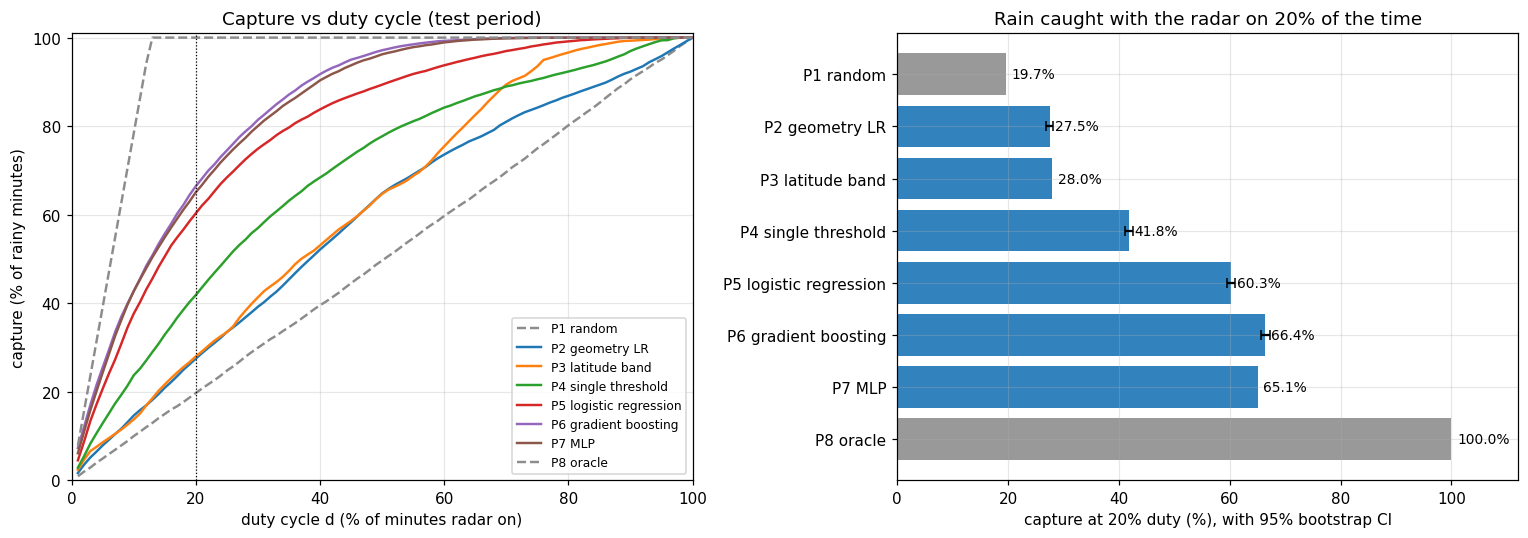

,auc,ap,capture@10%,capture@20%,capture@30%,mass_capture@20%
policy,,,,,,
P1 random,0.501,0.127,10.0%,19.7%,29.9%,20.2%
P2 geometry LR,0.593,0.166,14.6%,27.5%,39.2%,31.8%
P3 latitude band,0.629,0.179,13.7%,28.0%,41.3%,34.5%
P4 single threshold,0.718,0.263,23.7%,41.8%,57.0%,53.1%
P5 logistic regression,0.837,0.408,37.6%,60.3%,74.9%,71.7%
P6 gradient boosting,0.893,0.544,42.7%,66.4%,81.4%,72.7%
P7 MLP,0.889,0.527,42.7%,65.1%,80.0%,71.8%
P8 oracle,1.000,1.000,78.4%,100.0%,100.0%,91.7%


**Takeaway.** With the radar on 20% of the time, the best fixed policy (gradient boosting) catches **66.4%** of rainy minutes, versus 19.7% for random, 41.8% for a single-feature rule and 60.3% for logistic regression. That is **3.4x random**. The oracle shows the ceiling: at 20% duty it catches every rainy minute, because only 12.8% of test minutes are rainy. The small neural network (P7) reaches 65.1% with AUC 0.889, close to gradient boosting (0.893): two different non-linear models land at the same level, which suggests this is about the limit of what these passive features carry.

In [7]:
e3, curves, boot = r("e3_capture_table"), r("e3_capture_curves"), r("e10_bootstrap")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, g in curves.groupby("policy", sort=False):
    ref = name in ("P1 random", "P8 oracle")
    ax[0].plot(100 * g.d, 100 * g.capture, "--" if ref else "-", lw=1.6,
               color="0.55" if ref else None, label=name)
ax[0].axvline(20, color="k", lw=.8, ls=":")
ax[0].set(xlabel="duty cycle d (% of minutes radar on)", ylabel="capture (% of rainy minutes)",
          xlim=(0, 100), ylim=(0, 101), title="Capture vs duty cycle (test period)")
ax[0].legend(fontsize=8)

b = boot[boot.metric == "capture@20%"].set_index("policy")
bar = e3.set_index("policy")["capture@20%"]
colors = ["0.6" if p in ("P1 random", "P8 oracle") else "#3182bd" for p in bar.index]
ax[1].barh(bar.index, 100 * bar.values, color=colors)
for p in b.index:
    ax[1].errorbar(100 * b.loc[p, "mean"], p, xerr=[[100 * (b.loc[p, "mean"] - b.loc[p, "ci_low"])],
                   [100 * (b.loc[p, "ci_high"] - b.loc[p, "mean"])]], color="k", capsize=3)
for i, v in enumerate(bar.values):
    ax[1].text(100 * v + 1, i, f"{100 * v:.1f}%", va="center", fontsize=9)
ax[1].invert_yaxis(); ax[1].set_xlim(0, 112)
ax[1].set(xlabel="capture at 20% duty (%), with 95% bootstrap CI", title="Rain caught with the radar on 20% of the time")
plt.tight_layout(); plt.show()

show = e3.set_index("policy")[["auc", "ap", "capture@10%", "capture@20%", "capture@30%", "mass_capture@20%"]]
display(show.style.format({c: "{:.3f}" for c in ["auc", "ap"]} |
                          {c: "{:.1%}" for c in show.columns if "capture" in c}))

p6, p5, p4, p1 = (bar[k] for k in ["P6 gradient boosting", "P5 logistic regression", "P4 single threshold", "P1 random"])
display(Markdown(
    f"**Takeaway.** With the radar on 20% of the time, the best fixed policy (gradient boosting) "
    f"catches **{pct(p6)}** of rainy minutes, versus {pct(p1)} for random, {pct(p4)} for a "
    f"single-feature rule and {pct(p5)} for logistic regression. That is "
    f"**{p6 / p1:.1f}x random**. The oracle shows the ceiling: at 20% duty it catches every rainy "
    f"minute, because only {pct(curves.base_rate.iloc[0])} of test minutes are rainy. "
    f"The small neural network (P7) reaches {pct(bar['P7 MLP'])} with AUC "
    f"{e3.set_index('policy').auc['P7 MLP']:.3f}, close to gradient boosting "
    f"({e3.set_index('policy').auc['P6 gradient boosting']:.3f}): two different non-linear models "
    "land at the same level, which suggests this is about the limit of what these passive features carry."))

## E10. Are the differences real? (bootstrap confidence intervals)

The test period is resampled 1,000 times **by whole days** (minutes within a day are not
independent). Non-overlapping intervals mean the ranking is not a fluke of which days were
in the test set.

In [8]:
ci = boot.pivot(index="policy", columns="metric", values=["mean", "ci_low", "ci_high"])
tbl = pd.DataFrame({m: [f"{ci.loc[p, ('mean', m)]:.3f}  [{ci.loc[p, ('ci_low', m)]:.3f}, {ci.loc[p, ('ci_high', m)]:.3f}]"
                        for p in ci.index] for m in ["auc", "ap", "capture@13%", "capture@20%"]}, index=ci.index)
display(tbl)
order = ["P2 geometry LR", "P4 single threshold", "P5 logistic regression", "P6 gradient boosting"]
overlap = [(a, b_) for a, b_ in zip(order, order[1:])
           if ci.loc[a, ("ci_high", "capture@20%")] >= ci.loc[b_, ("ci_low", "capture@20%")]]
display(Markdown("**Takeaway.** " + ("Every step up the ladder (geometry → single feature → linear → "
        "boosting) has non-overlapping 95% intervals for capture@20%: each step is a real improvement."
        if not overlap else f"Overlapping intervals: {overlap}.")))

,auc,ap,capture@13%,capture@20%
policy,,,,
P2 geometry LR,"0.593 [0.589, 0.598]","0.166 [0.162, 0.169]","0.181 [0.177, 0.187]","0.275 [0.269, 0.281]"
P4 single threshold,"0.718 [0.715, 0.722]","0.263 [0.256, 0.270]","0.290 [0.282, 0.297]","0.418 [0.410, 0.426]"
P5 logistic regression,"0.837 [0.834, 0.840]","0.409 [0.400, 0.417]","0.455 [0.449, 0.461]","0.603 [0.596, 0.610]"
P6 gradient boosting,"0.893 [0.891, 0.896]","0.544 [0.536, 0.553]","0.508 [0.500, 0.516]","0.664 [0.656, 0.673]"


**Takeaway.** Every step up the ladder (geometry → single feature → linear → boosting) has non-overlapping 95% intervals for capture@20%: each step is a real improvement.

## E1. Why the split matters: random rows vs a time-blocked split

A random split puts neighbouring minutes, which share the same 30-minute weather snapshot,
on both sides of train/test. That leaks information and can flatter the model.

In [9]:
e1 = r("e1_split").set_index("split")
display(e1[["n_train", "n_test", "duty", "capture", "mass_capture", "precision", "lift", "auc", "ap"]].round(3))
rb, tb = e1.loc["random 30%"], e1.loc["time-blocked"]
display(Markdown(
    f"**Takeaway.** Logistic regression at 13% duty: AUC {rb.auc:.3f} (random split) vs {tb.auc:.3f} "
    f"(time-blocked); capture {pct(rb.capture)} vs {pct(tb.capture)}. The gap is "
    f"{'small' if abs(rb.auc - tb.auc) < 0.01 else 'noticeable'}: for this linear model, leakage "
    "between neighbouring minutes does not inflate the score much, but the paper reports the "
    "time-blocked numbers because they are the honest test of generalising to new weather."))

,n_train,n_test,duty,capture,mass_capture,precision,lift,auc,ap
split,,,,,,,,,
random 30%,211855,105819,0.129,0.439,0.555,0.463,3.407,0.833,0.412
time-blocked,174750,133350,0.127,0.455,0.598,0.457,3.586,0.837,0.408


**Takeaway.** Logistic regression at 13% duty: AUC 0.833 (random split) vs 0.837 (time-blocked); capture 43.9% vs 45.5%. The gap is small: for this linear model, leakage between neighbouring minutes does not inflate the score much, but the paper reports the time-blocked numbers because they are the honest test of generalising to new weather.

## E2. Does skill hold across months?

Each month is held out in turn, and the model is trained on all the others (Feb 2006 has
only one day, so it is merged into January).

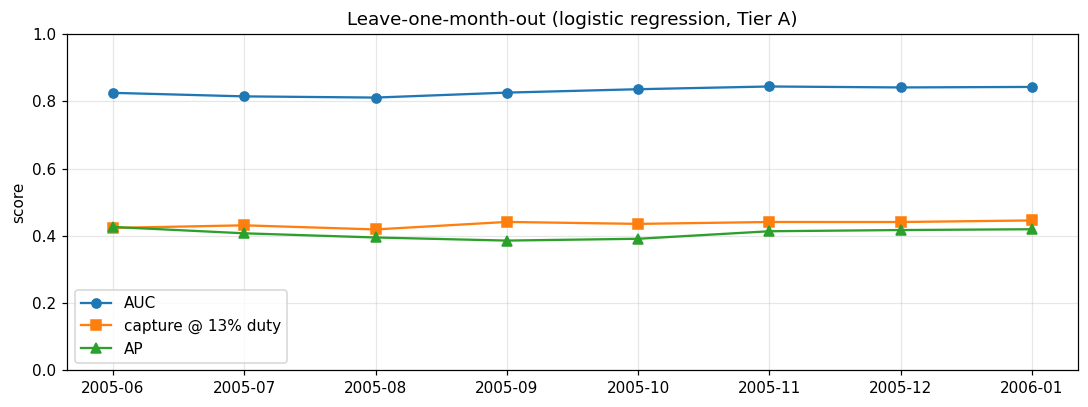

,n_test,auc,ap,capture@13%,capture@base_rate
held_out,,,,,
2005-06,42240,0.825,0.426,0.424,0.440
2005-07,44580,0.815,0.408,0.431,0.442
2005-08,44580,0.811,0.395,0.419,0.432
2005-09,43140,0.826,0.386,0.441,0.462
2005-10,44580,0.836,0.391,0.436,0.458
2005-11,43140,0.844,0.414,0.441,0.464
2005-12,44580,0.842,0.417,0.441,0.459
2006-01,45480,0.843,0.420,0.446,0.464


**Takeaway.** AUC stays between 0.811 and 0.844 across all 8 months (spread 0.033): the skill is not tied to one season.

In [10]:
e2 = r("e2_leave_one_month_out")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(e2.held_out, e2.auc, marker="o", label="AUC")
ax.plot(e2.held_out, e2["capture@13%"], marker="s", label="capture @ 13% duty")
ax.plot(e2.held_out, e2.ap, marker="^", label="AP")
ax.set(ylim=(0, 1), ylabel="score", title="Leave-one-month-out (logistic regression, Tier A)")
ax.legend(); plt.tight_layout(); plt.show()
display(e2.round(3).set_index("held_out"))
display(Markdown(f"**Takeaway.** AUC stays between {e2.auc.min():.3f} and {e2.auc.max():.3f} across "
                 f"all {len(e2)} months (spread {e2.auc.max() - e2.auc.min():.3f}): the skill is not "
                 "tied to one season."))

## E4. Label geometry: nadir rain vs swath rain

Train on one definition of "rain" and score on the other. The CPR only measures the nadir
line, so a policy credited with swath rain is credited with rain the radar never sees.

In [11]:
e4 = r("e4_label_geometry")
grid = e4.pivot(index="trained_on", columns="scored_on", values="capture@20%")
display(grid.style.format("{:.1%}").set_caption("capture @ 20% duty"))
display(e4.pivot(index="trained_on", columns="scored_on", values="auc").round(3).style.set_caption("AUC"))
e4m = meta["e4"]
display(Markdown(
    f"**Takeaway.** Rain occurs in {pct(e4m['positive_rate']['prectot_nadir'])} of minutes at nadir "
    f"but {pct(e4m['positive_rate']['prectot_swath'])} in the swath, and "
    f"**{pct(e4m['swath_pos_label_neg_share'])} of swath-rainy minutes have no rain at nadir**. "
    f"The ranking is equally good either way (AUC ≈ {e4.auc.mean():.2f}), but capture at nadir is "
    f"{pct(grid.loc['prectot_nadir', 'prectot_nadir'])} vs {pct(grid.loc['prectot_nadir', 'prectot_swath'])} "
    "on the swath label: which label you choose changes the reported number a lot, so it has to "
    "match the radar's footprint."))

scored_on,prectot_nadir,prectot_swath
trained_on,,
prectot_nadir,66.4%,51.1%
prectot_swath,64.7%,50.7%


scored_on,prectot_nadir,prectot_swath
trained_on,,
prectot_nadir,0.893000,0.897000
prectot_swath,0.890000,0.899000


**Takeaway.** Rain occurs in 12.8% of minutes at nadir but 27.9% in the swath, and **54.2% of swath-rainy minutes have no rain at nadir**. The ranking is equally good either way (AUC ≈ 0.89), but capture at nadir is 66.4% vs 51.1% on the swath label: which label you choose changes the reported number a lot, so it has to match the radar's footprint.

## E5. Day vs night: what do we lose without sunlight?

Optical depth (`tautot`) needs reflected sunlight, so at night the MSI has only thermal
channels. Tiers remove features step by step:

| tier | features |
|---|---|
| A | everything (cloud fraction, cloud-top temperature, optical depth, longwave, geometry) |
| A_notau | A without optical depth (what is available at night) |
| B | thermal only: cloud-top temperature and longwave, plus geometry |
| C | geometry only |

"Switched" uses the tier's day model by day and its no-optical-depth version at night,
which is how a real policy would run.

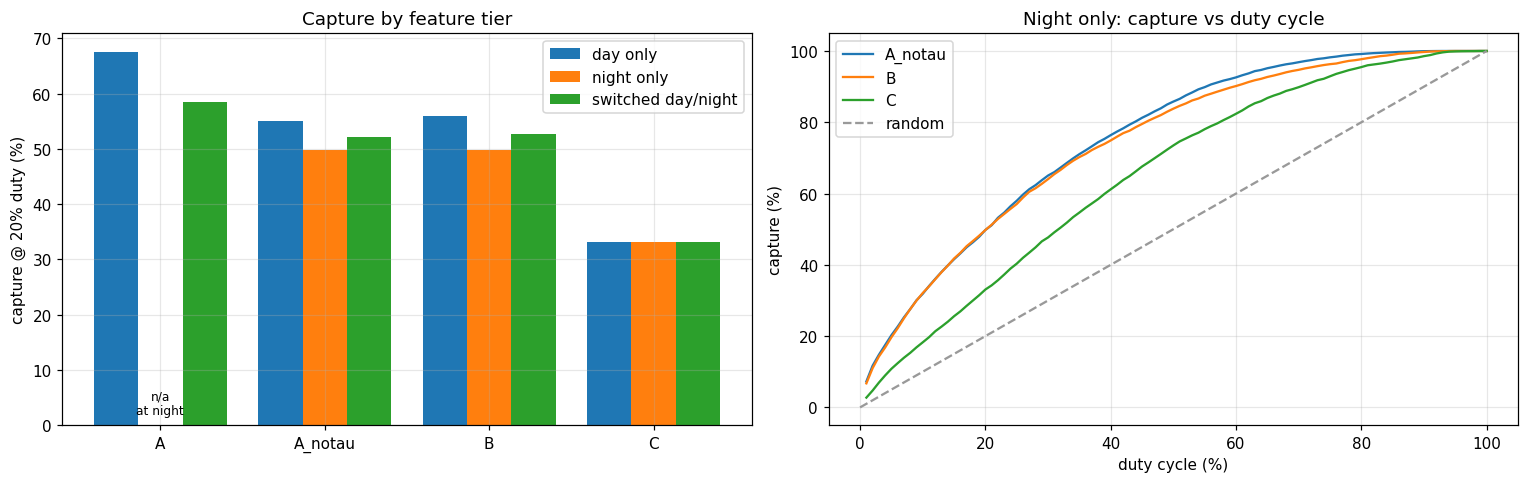

,day_capture@20%,night_capture@20%,switched_capture@20%,retention_vs_A
tier,,,,
A,0.676,n/a (no optical depth at night),0.585,1.000
A_notau,0.551,0.498,0.521,0.892
B,0.559,0.498,0.527,0.902
C,0.332,0.331,0.332,0.567


**Takeaway.** Running day/night switched, dropping optical depth keeps **89.2%** of Tier A's capture, and thermal-only (B) keeps 90.2%. Geometry alone (C) keeps 56.7%. At night the best tiers catch 49.8% at 20% duty, vs 67.6% by day with optical depth: the passive signal is weaker at night but still far above geometry alone.

In [12]:
e5, night = r("e5_tiers"), r("e5_night_curves")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(e5)); w = 0.27
for i, (c, lb) in enumerate([("day_capture@20%", "day only"), ("night_capture@20%", "night only"),
                             ("switched_capture@20%", "switched day/night")]):
    ax[0].bar(x + (i - 1) * w, 100 * e5[c], w, label=lb)
ax[0].set(xticks=x, xticklabels=e5.tier, ylabel="capture @ 20% duty (%)", title="Capture by feature tier")
for i in np.flatnonzero(e5["night_capture@20%"].isna()):
    ax[0].text(x[i], 2, "n/a\nat night", ha="center", fontsize=8)
ax[0].legend()
for name, g in night.groupby("tier", sort=False):
    ax[1].plot(100 * g.d, 100 * g.capture, label=name)
ax[1].plot([0, 100], [0, 100], "--", color="0.6", label="random")
ax[1].set(xlabel="duty cycle (%)", ylabel="capture (%)", title="Night only: capture vs duty cycle")
ax[1].legend(); plt.tight_layout(); plt.show()
display(e5.set_index("tier").style.format("{:.3f}", na_rep="n/a (no optical depth at night)"))
t = e5.set_index("tier")
display(Markdown(
    f"**Takeaway.** Running day/night switched, dropping optical depth keeps "
    f"**{pct(t.loc['A_notau', 'retention_vs_A'])}** of Tier A's capture, and thermal-only (B) keeps "
    f"{pct(t.loc['B', 'retention_vs_A'])}. Geometry alone (C) keeps {pct(t.loc['C', 'retention_vs_A'])}. "
    f"At night the best tiers catch {pct(t['night_capture@20%'].max())} at 20% duty, vs "
    f"{pct(t.loc['A', 'day_capture@20%'])} by day with optical depth: the passive signal is weaker "
    "at night but still far above geometry alone."))

## E6. Where does the policy work best?

One global threshold (set for 20% duty overall) applied to each region. "Duty" shows how much
of the budget each region ends up using.

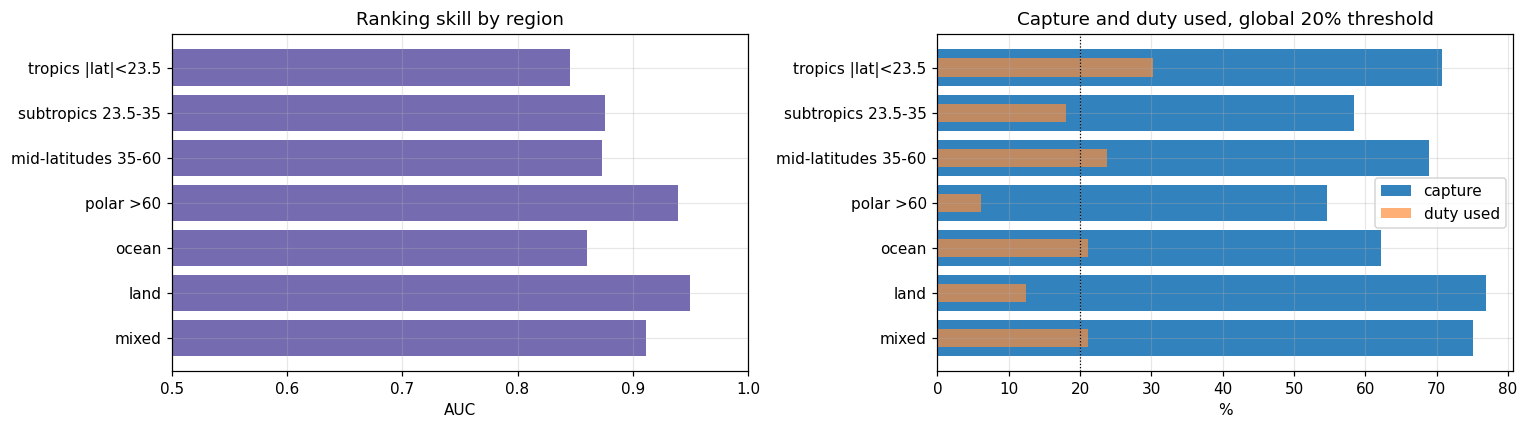

,n,base_rate,auc,duty,capture@20%
stratum,,,,,
tropics |lat|<23.5,34871,0.193,0.846,0.302,0.707
subtropics 23.5-35,17130,0.145,0.876,0.181,0.584
mid-latitudes 35-60,37706,0.156,0.874,0.238,0.689
polar >60,43643,0.044,0.940,0.062,0.546
ocean,76970,0.153,0.861,0.211,0.623
land,33504,0.067,0.950,0.124,0.769
mixed,22876,0.131,0.912,0.212,0.751


**Takeaway.** Ranking is strongest over land (AUC 0.950) and at high latitudes (0.940), where rain is rare (6.7% and 4.4% of minutes). The tropics have the most rain (19.3% of minutes) and use 30.2% duty under the global threshold, against 6.2% in polar regions: a single threshold spends the budget where rain is most frequent.

In [13]:
e6 = r("e6_strata").set_index("stratum")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(e6.index, e6.auc, color="#756bb1"); ax[0].set(xlim=(0.5, 1), xlabel="AUC", title="Ranking skill by region")
ax[1].barh(e6.index, 100 * e6["capture@20%"], color="#3182bd", label="capture")
ax[1].barh(e6.index, 100 * e6.duty, color="#fd8d3c", alpha=.7, height=.4, label="duty used")
ax[1].axvline(20, color="k", ls=":", lw=.8)
ax[1].set(xlabel="%", title="Capture and duty used, global 20% threshold"); ax[1].legend()
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()
display(e6.round(3))
display(Markdown(
    f"**Takeaway.** Ranking is strongest over land (AUC {e6.loc['land', 'auc']:.3f}) and at high "
    f"latitudes ({e6.loc['polar >60', 'auc']:.3f}), where rain is rare "
    f"({pct(e6.loc['land', 'base_rate'])} and {pct(e6.loc['polar >60', 'base_rate'])} of minutes). The tropics have the most rain ({pct(e6.loc['tropics |lat|<23.5', 'base_rate'])} of minutes) "
    f"and use {pct(e6.loc['tropics |lat|<23.5', 'duty'])} duty under the global threshold, against "
    f"{pct(e6.loc['polar >60', 'duty'])} in polar regions: a single threshold spends the budget where "
    "rain is most frequent."))

## E7. Does the conclusion depend on the rain threshold?

In [14]:
e7 = r("e7_label_sensitivity")
e7["threshold (mm/hr)"] = (e7.threshold_kg_m2_s * MM).round(3)
piv = e7.pivot(index="label", columns="model", values=["base_rate_test", "auc", "ap", "capture@d=base_rate"])
display(piv.round(3))
lg = e7[e7.model == "lgbm"].set_index("label")
lr = e7[e7.model == "lr"].set_index("label")
wins = int((lg.auc > lr.auc.reindex(lg.index)).sum())
display(Markdown(
    "Here the duty cycle is set equal to each label's rain rate, so a perfect policy would catch 100%. "
    f"**Takeaway.** Gradient boosting beats logistic regression in AUC on {wins} of {len(lr)} labels "
    f"(boosting AUC {lg.auc.min():.3f}–{lg.auc.max():.3f}). The rare labels (≥ 5 mm/hr: "
    f"{pct(lg.loc['prectot_nadir >= 5 mm/hr', 'base_rate_test'])} of minutes; convective ≥ 1 mm/hr: "
    f"{pct(lg.loc['preccon_nadir >= 1 mm/hr', 'base_rate_test'])}) have high AUC but low AP "
    f"({lg.loc['prectot_nadir >= 5 mm/hr', 'ap']:.3f} and {lg.loc['preccon_nadir >= 1 mm/hr', 'ap']:.3f}): "
    "they are ranked above most dry minutes, but a budget equal to their rarity catches only "
    f"{pct(lg.loc['prectot_nadir >= 5 mm/hr', 'capture@d=base_rate'])} and "
    f"{pct(lg.loc['preccon_nadir >= 1 mm/hr', 'capture@d=base_rate'])} of them."))

base_rate_test           auc            ap        capture@d=base_rate       
model                                                 lgbm     lr   lgbm     lr   lgbm     lr                lgbm     lr
label                                                                                                                   
preccon_nadir >= 1 mm/hr                             0.012  0.012  0.957  0.929  0.195  0.136               0.304  0.184
prectot_nadir > train median (median split)          0.468  0.468  0.926  0.882  0.913  0.850               0.833  0.806
prectot_nadir >= 0.1 mm/hr                           0.477  0.477  0.926  0.883  0.915  0.855               0.837  0.810
prectot_nadir >= 1 mm/hr                             0.128  0.128  0.893  0.837  0.544  0.408               0.549  0.497
prectot_nadir >= 5 mm/hr                             0.036  0.036  0.922  0.877  0.307  0.206               0.411  0.287

Here the duty cycle is set equal to each label's rain rate, so a perfect policy would catch 100%. **Takeaway.** Gradient boosting beats logistic regression in AUC on 5 of 5 labels (boosting AUC 0.893–0.957). The rare labels (≥ 5 mm/hr: 3.6% of minutes; convective ≥ 1 mm/hr: 1.2%) have high AUC but low AP (0.307 and 0.195): they are ranked above most dry minutes, but a budget equal to their rarity catches only 41.1% and 30.4% of them.

## E8. Missing data and E9. Policy cost

In [15]:
display(r("e8_missing_data").fillna("").set_index("item"))
e9 = r("e9_policy_cost").set_index("policy")
display(e9)
display(Markdown(
    f"**Takeaway.** No targets are missing. Feature gaps (cloud-top temperature where there is no "
    f"cloud, the last-minute-of-step forecast) are handled by imputation or natively by LightGBM. "
    f"On cost: logistic regression is {int(e9.loc['P5 logistic regression', 'parameters'])} parameters "
    f"(~{e9.loc['P5 logistic regression', 'serialized_bytes'] / 1e3:.0f} kB), while gradient boosting is "
    f"{int(e9.loc['P6 gradient boosting', 'parameters']):,} parameters "
    f"(~{e9.loc['P6 gradient boosting', 'serialized_bytes'] / 1e6:.1f} MB). Both take under 1 ms per "
    f"decision in Python, against a 60 s decision interval. Boosting's extra "
    f"{100 * (bar['P6 gradient boosting'] - bar['P5 logistic regression']):.1f} points of capture@20% cost "
    f"{e9.loc['P6 gradient boosting', 'serialized_bytes'] / e9.loc['P5 logistic regression', 'serialized_bytes']:.0f}x "
    "the model size."))

,count,note
item,,
rows in dataset,352800.0,
rows with invalid prectot_nadir,0.0,
rows with invalid prectot_swath,0.0,
rows with any NaN Tier A feature,28608.0,
NaN in cldtmp_mean,17425.0,
NaN in lwtup_fore,11760.0,
train rows used (valid label),174750.0,
val rows used (valid label),44580.0,
test rows used (valid label),133350.0,


,inputs,parameters,operations,serialized_bytes,wall_ms_per_decision_python
policy,,,,,
P2 geometry LR,7,8,~7 multiply-adds + 1 sigmoid,2772,0.751648
P5 logistic regression,13,16,~15 multiply-adds + 1 sigmoid,3278,0.802999
P6 gradient boosting,13,18300,"~3346 comparisons (300 trees, mean depth 11.2)",1049169,0.548206
P7 MLP,13,5249,~5120 multiply-adds,134413,0.792886


**Takeaway.** No targets are missing. Feature gaps (cloud-top temperature where there is no cloud, the last-minute-of-step forecast) are handled by imputation or natively by LightGBM. On cost: logistic regression is 16 parameters (~3 kB), while gradient boosting is 18,300 parameters (~1.0 MB). Both take under 1 ms per decision in Python, against a 60 s decision interval. Boosting's extra 6.1 points of capture@20% cost 320x the model size.

## E11. Which passive features matter?

Two views. **Permutation importance**: shuffle one feature and see how much the best model's
AUC drops. **Single-feature AUC**: how well each feature ranks rain on its own.

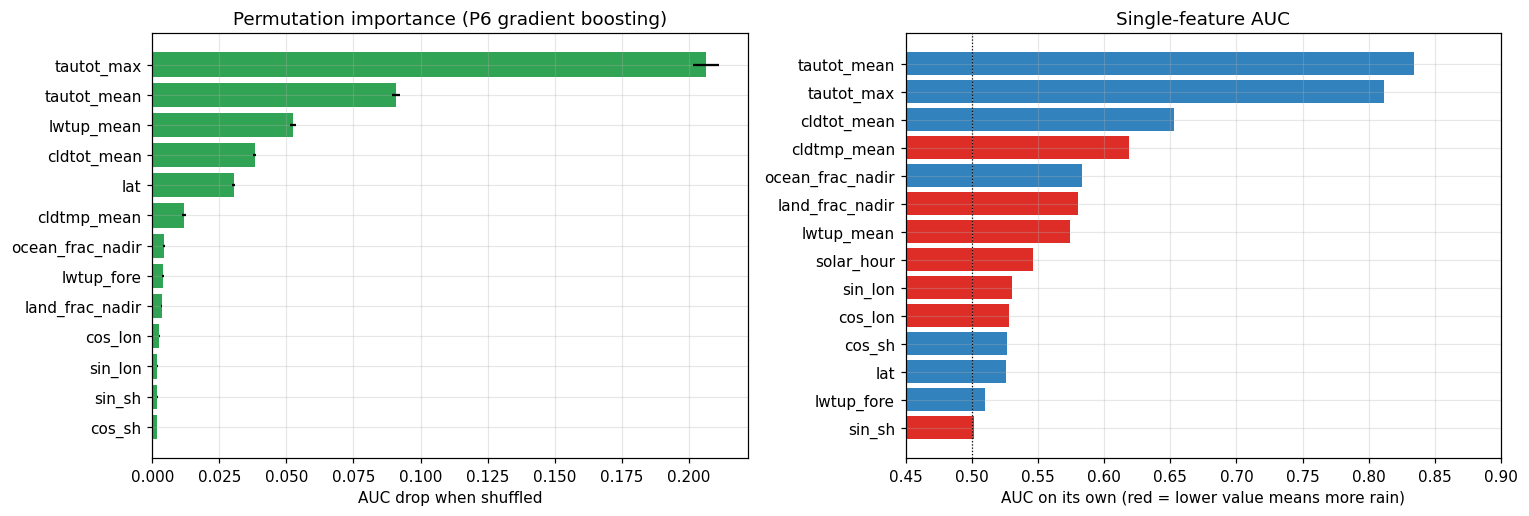

**Takeaway.** The model leans most on **tautot_max** and **tautot_mean** (optical depth), then lwtup_mean and cldtot_mean. The best single feature, `tautot_mean`, reaches AUC 0.834 on its own, about as good as logistic regression on all features (0.837). Gradient boosting reaches 0.893: the extra skill comes from non-linear combinations of optical depth with the other features, not from any one additional feature.

In [16]:
e3i_auc = e3.set_index("policy").auc
perm = r("e11_permutation_importance").sort_values("auc_drop_mean")
single = r("e11_single_feature_auc").sort_values("auc")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(perm.feature, perm.auc_drop_mean, xerr=perm.auc_drop_std, color="#31a354")
ax[0].set(xlabel="AUC drop when shuffled", title=f"Permutation importance ({meta['e11_best_policy']})")
ax[1].barh(single.feature, single.auc, color=["#de2d26" if i else "#3182bd" for i in single.inverted])
ax[1].axvline(0.5, color="k", ls=":", lw=.8)
ax[1].set(xlim=(0.45, 0.9), xlabel="AUC on its own (red = lower value means more rain)",
          title="Single-feature AUC")
plt.tight_layout(); plt.show()
top = perm.sort_values("auc_drop_mean", ascending=False).feature.tolist()
display(Markdown(
    f"**Takeaway.** The model leans most on **{top[0]}** and **{top[1]}** (optical depth), then "
    f"{top[2]} and {top[3]}. The best single feature, `{single.feature.iloc[-1]}`, reaches AUC "
    f"{single.auc.iloc[-1]:.3f} on its own, about as good as logistic regression on all features "
    f"({e3i_auc['P5 logistic regression']:.3f}). Gradient boosting reaches "
    f"{e3i_auc['P6 gradient boosting']:.3f}: the extra skill comes from non-linear combinations of "
    "optical depth with the other features, not from any one additional feature."))

## Summary

In [17]:
e3i = e3.set_index("policy")
summary = pd.DataFrame({
    "value": [f"{len(rows):,} one-minute decisions, G5NR weather 2005-06-01 .. 2006-02-01",
              pct(curves.base_rate.iloc[0]),
              f"{pct(e3i.loc['P6 gradient boosting', 'capture@20%'])} (random {pct(e3i.loc['P1 random', 'capture@20%'])})",
              f"{e3i.loc['P6 gradient boosting', 'auc']:.3f}",
              f"{pct(e3i.loc['P6 gradient boosting', 'mass_capture@20%'])}",
              f"{pct(t.loc['A_notau', 'retention_vs_A'])} of full skill",
              f"{e2.auc.min():.3f} – {e2.auc.max():.3f}",
              ", ".join(top[:3])]},
    index=["dataset", "rainy minutes in test (>= 1 mm/hr at nadir)", "best baseline capture @ 20% duty",
           "best baseline AUC", "best baseline rain-amount capture @ 20%",
           "without optical depth (night-capable)", "AUC range across months", "most important features"])
display(summary)

,value
dataset,"352,800 one-minute decisions, G5NR weather 200..."
rainy minutes in test (>= 1 mm/hr at nadir),12.8%
best baseline capture @ 20% duty,66.4% (random 19.7%)
best baseline AUC,0.893
best baseline rain-amount capture @ 20%,72.7%
without optical depth (night-capable),89.2% of full skill
AUC range across months,0.811 – 0.844
most important features,"tautot_max, tautot_mean, lwtup_mean"


**What this means for the RL work.** These are the numbers to beat: a learned gating policy
under the same 20% budget has to catch more than the gradient-boosting baseline's share of rainy
minutes on the same test period, or show that it uses the budget better (for example, by
adapting the duty cycle to the weather it sees, which a fixed threshold cannot do).

CSV and Cesium exports for visualisation are produced by `task_outputs/export_trackwise.py`
into `exports/` (not in git).